In [17]:
# # Model 2 — Random Forest

# Random Forest is evaluated as the second machine learning algorithm.

# Based on the Logistic Regression experiment, Smote was selected as the preferred approach for handling class imbalance.
# Therefore, Random Forest is trained using Smote to generate synthetic samples for the minority class.

In [18]:
# Model 2 — Random Forest

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from imblearn.over_sampling import SMOTE

print("All libraries imported successfully.")

All libraries imported successfully.


In [19]:
# Load original training data (before SMOTE)

X_train = pd.read_csv("../Data/processed/X_train.csv")
y_train = pd.read_csv("../Data/processed/y_train.csv").squeeze()

# Load original untouched test data

X_test = pd.read_csv("../Data/processed/X_test.csv")
y_test = pd.read_csv("../Data/processed/y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nOriginal training class distribution:")
print(y_train.value_counts())

print("\nOriginal testing class distribution:")
print(y_test.value_counts())

X_train: (198608, 30)
y_train: (198608,)
X_test: (85118, 30)
y_test: (85118,)

Original training class distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Original testing class distribution:
Class
0    84976
1      142
Name: count, dtype: int64


In [20]:
# Split original training data into 80% training and 20% validation

X_train_rf, X_val_rf, y_train_rf, y_val_rf = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Shape:", X_train_rf.shape)
print("Validation Shape:", X_val_rf.shape)

print("\nTraining Class Distribution:")
print(y_train_rf.value_counts())

print("\nValidation Class Distribution:")
print(y_val_rf.value_counts())

Training Shape: (158886, 30)
Validation Shape: (39722, 30)

Training Class Distribution:
Class
0    158621
1       265
Name: count, dtype: int64

Validation Class Distribution:
Class
0    39656
1       66
Name: count, dtype: int64


In [21]:
# Apply SMOTE only on the training subset
# Validation and test data remain untouched

smote = SMOTE(random_state=42)

X_train_smote_rf, y_train_smote_rf = smote.fit_resample(
    X_train_rf,
    y_train_rf
)

print("Training data after SMOTE:")
print(X_train_smote_rf.shape)

print("\nClass distribution after SMOTE:")
print(y_train_smote_rf.value_counts())

print("\nValidation data remains unchanged:")
print(y_val_rf.value_counts())

print("\nTest data remains unchanged:")
print(y_test.value_counts())

Training data after SMOTE:
(317242, 30)

Class distribution after SMOTE:
Class
0    158621
1    158621
Name: count, dtype: int64

Validation data remains unchanged:
Class
0    39656
1       66
Name: count, dtype: int64

Test data remains unchanged:
Class
0    84976
1      142
Name: count, dtype: int64


In [22]:
# Random Forest is an ensemble learning algorithm
# that combines multiple decision trees.

# It can capture non-linear relationships between
# transaction features and the fraud class.

# SMOTE is used to handle class imbalance.
# The original validation and test datasets remain untouched.

In [23]:
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2
)

print("Random Forest model created successfully.")

Random Forest model created successfully.


In [24]:
# Train using SMOTE-balanced training data

model_rf.fit(
    X_train_smote_rf,
    y_train_smote_rf
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [25]:
# Generate fraud probabilities on validation data

y_val_prob_rf = model_rf.predict_proba(X_val_rf)[:, 1]

# Test different classification thresholds

thresholds = [
    0.1, 0.2, 0.3, 0.4, 0.5,
    0.6, 0.7, 0.8, 0.9
]

results = []

for threshold in thresholds:

    y_val_pred = (y_val_prob_rf >= threshold).astype(int)

    precision = precision_score(
        y_val_rf,
        y_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val_rf,
        y_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val_rf,
        y_val_pred,
        zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

threshold_results = pd.DataFrame(results)

print("Validation Threshold Comparison:")
display(threshold_results.round(4))

# Select threshold with the highest validation F1-score

best_index = threshold_results["F1-Score"].idxmax()

final_threshold = threshold_results.loc[
    best_index, "Threshold"
]

print("\nSelected Threshold:", final_threshold)

Validation Threshold Comparison:


,Threshold,Precision,Recall,F1-Score
0,0.1,0.2872,0.8485,0.4291
1,0.2,0.6506,0.8182,0.7248
2,0.3,0.8060,0.8182,0.8120
3,0.4,0.8852,0.8182,0.8504
4,0.5,0.9000,0.8182,0.8571
5,0.6,0.9298,0.8030,0.8618
6,0.7,0.9259,0.7576,0.8333
7,0.8,0.9400,0.7121,0.8103
8,0.9,0.9535,0.6212,0.7523



Selected Threshold: 0.6


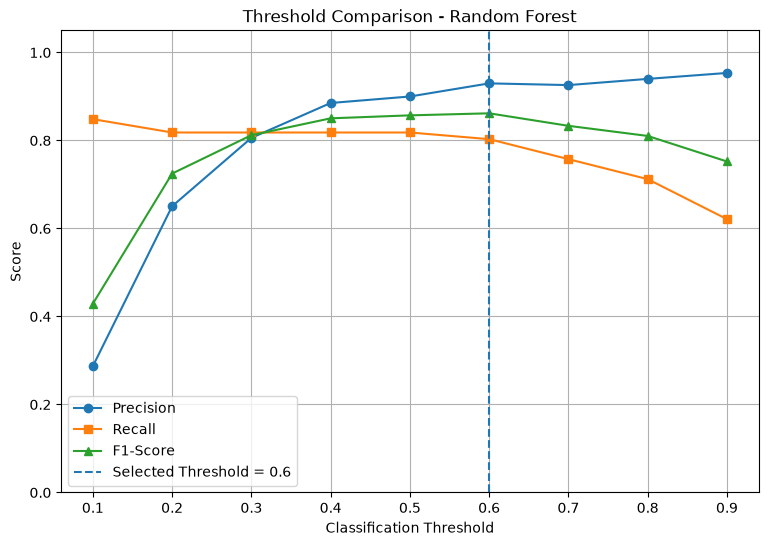

In [38]:
# Plot threshold comparison using validation results

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1-Score"],
    marker="^",
    label="F1-Score"
)

plt.axvline(
    x=final_threshold,
    linestyle="--",
    label=f"Selected Threshold = {final_threshold}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title("Threshold Comparison - Random Forest")

plt.xticks(thresholds)
plt.ylim(0, 1.05)

plt.legend()
plt.grid()
plt.show()

In [26]:
# Generate fraud probabilities on original test data

y_prob_rf = model_rf.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data

y_pred_rf = (y_prob_rf >= final_threshold).astype(int)

print("Test predictions generated successfully.")

Test predictions generated successfully.


In [27]:
print("Classification Report — Random Forest with SMOTE")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Genuine", "Fraud"]
    )
)

Classification Report — Random Forest with SMOTE
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     84976
       Fraud       0.96      0.57      0.72       142

    accuracy                           1.00     85118
   macro avg       0.98      0.79      0.86     85118
weighted avg       1.00      1.00      1.00     85118



In [28]:
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print("Random Forest Final Test Results")

print("Precision:", round(precision_rf, 4))
print("Recall:", round(recall_rf, 4))
print("F1-score:", round(f1_rf, 4))
print("ROC-AUC:", round(roc_auc_rf, 4))
print("PR-AUC:", round(pr_auc_rf, 4))

Random Forest Final Test Results
Precision: 0.9643
Recall: 0.5704
F1-score: 0.7168
ROC-AUC: 0.9669
PR-AUC: 0.8204


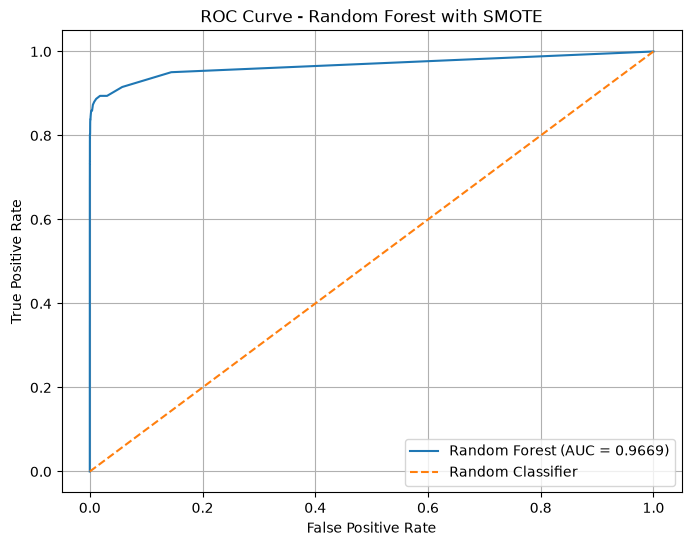

In [36]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve using untouched test data

fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob_rf)

roc_auc = roc_auc_score(y_test, y_prob_rf)

# Plot ROC curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Random Forest with SMOTE")

plt.legend()
plt.grid()
plt.show()

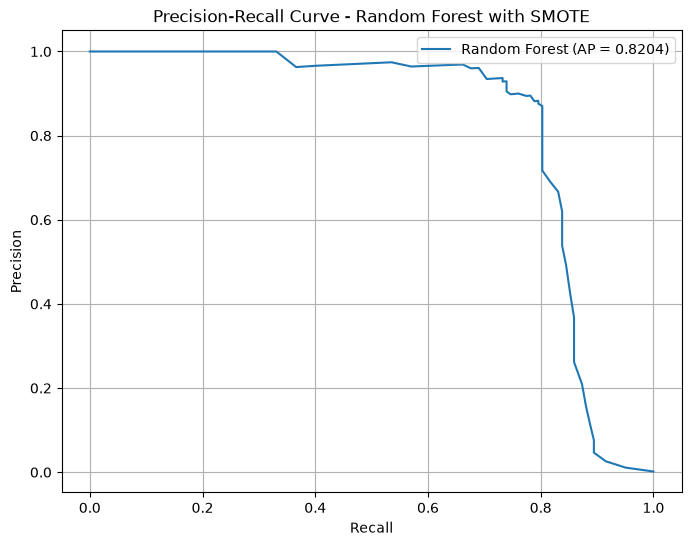

In [37]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate Precision-Recall curve

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob_rf
)

average_precision = average_precision_score(y_test, y_prob_rf)

# Plot Precision-Recall curve

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Random Forest (AP = {average_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve - Random Forest with SMOTE")

plt.legend()
plt.grid()
plt.show()

Confusion Matrix:
[[84973     3]
 [   61    81]]


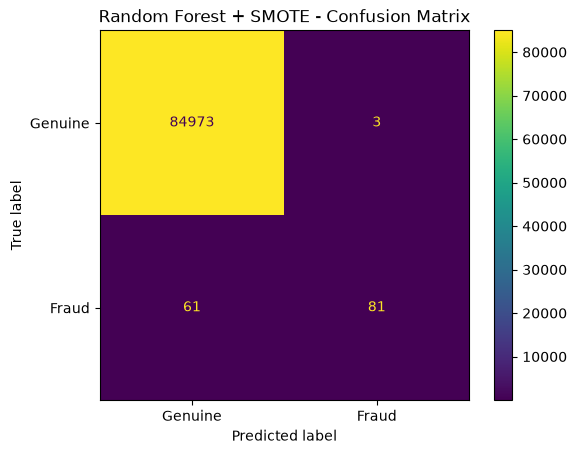

In [29]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Genuine", "Fraud"]
)

disp.plot()

plt.title("Random Forest + SMOTE - Confusion Matrix")
plt.show()

In [30]:
rf_results = {
    "Model": "Random Forest",
    "Technique": "SMOTE",
    "Threshold": final_threshold,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1-score": f1_rf,
    "ROC-AUC": roc_auc_rf,
    "PR-AUC": pr_auc_rf
}

rf_results_df = pd.DataFrame([rf_results])

display(rf_results_df.round(4))

,Model,Technique,Threshold,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Random Forest,SMOTE,0.6,0.9643,0.5704,0.7168,0.9669,0.8204


In [31]:
# Get feature importance from Random Forest

feature_importance = pd.DataFrame({
    "Feature": X_train_smote_rf.columns,
    "Importance": model_rf.feature_importances_
})

# Sort features by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")

display(feature_importance.head(15).round(4))

Top 15 Important Features:


,Feature,Importance
14,V14,0.2132
10,V10,0.1237
12,V12,0.1197
4,V4,0.1059
17,V17,0.0958
3,V3,0.0741
11,V11,0.0480
16,V16,0.0405
2,V2,0.0404
9,V9,0.0278


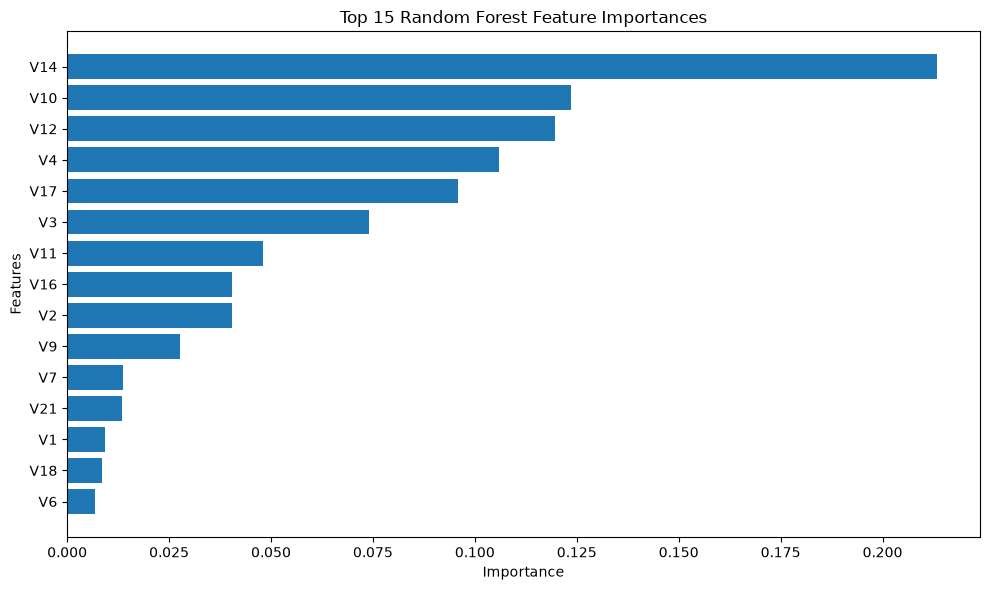

In [32]:
# Visualize top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Random Forest Feature Importances")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()